In [310]:
import sys
import csv
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
 
import numpy as np

sys.path.insert(0, "../")
from utils import pos_to_electrode_map, get_electrode_subsets


In [311]:
def stripplot_alpha(data: pd.DataFrame,
                    x: str        = 'Mean R2',
                    y: str        = 'Count',
                    hue: str      = 'Spacing',
                    order         = None,
                    ax            = None,
                    palette       = 'viridis',
                    alpha_min: float = 0.15,
                    alpha_max: float = 0.90,
                    jitter: float = 0.25,
                    point_size: float = 4.0,
                    dodge: bool   = True):
    """
    Matplotlib re-implementation of sns.stripplot with dodge=True,
    where each point's alpha is scaled by the number of points in its
    (y-category, hue) group.
 
    Parameters
    ----------
    data       : DataFrame
    x          : column for the continuous axis
    y          : column for the categorical axis (rows)
    hue        : column used for colour + dodge
    order      : list of y-category values in display order (top→bottom)
    ax         : existing Axes to draw on (creates one if None)
    palette    : matplotlib colormap name
    alpha_min  : minimum opacity (group with fewest points)
    alpha_max  : maximum opacity (group with most points)
    jitter     : fraction of the dodge lane to jitter within
    point_size : scatter marker size (points²)
    dodge      : offset hue groups vertically (True mirrors seaborn dodge)
    """
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, len(order or data[y].unique()) * 0.7 + 1))
 
    if order is None:
        order = list(data[y].cat.categories) if hasattr(data[y], 'cat') else list(data[y].unique())
    print(order)
    hue_levels = sorted(data[hue].unique())
    n_hue      = len(hue_levels)
 
    # ── Colour map ────────────────────────────────────────────────────────────
    cmap      = mcolors.LinearSegmentedColormap.from_list(
                    '', plt.colormaps[palette](np.linspace(0, 1, n_hue)))
    color_map = {h: cmap(i / max(n_hue - 1, 1)) for i, h in enumerate(hue_levels)}
 
    # ── Group counts for alpha scaling ────────────────────────────────────────
    group_n = (data.groupby([y, hue], observed=True)
                   .size()
                   .rename('n')
                   .reset_index())
    n_min, n_max = group_n['n'].min(), group_n['n'].max()
 
    def alpha_for(n):
        if n_max == n_min:
            return (alpha_min + alpha_max) / 2
        return alpha_min + (n - n_min) / (n_max - n_min) * (alpha_max - alpha_min)
 
    alpha_map = {(row[y], row[hue]): alpha_for(row['n'])
                 for _, row in group_n.iterrows()}
 
    # ── Dodge layout ──────────────────────────────────────────────────────────
    dodge_span = 0.72                          # fraction of one row height
    dodge_step = dodge_span / n_hue
    dodge_offsets = {h: -dodge_span / 2 + dodge_step * i + dodge_step / 2
                     for i, h in enumerate(hue_levels)}
 
    # ── Draw points ───────────────────────────────────────────────────────────
    for row_idx, cat in enumerate(order):
        subset = data[data[y] == cat]
        for hue_val in hue_levels:
            pts = subset[subset[hue] == hue_val][x].values
            if len(pts) == 0:
                continue
 
            alpha  = alpha_map.get((cat, hue_val), (alpha_min + alpha_max) / 2)
            color  = color_map[hue_val]
            y_base = row_idx + (dodge_offsets[hue_val] if dodge else 0)
            y_pts  = y_base + np.random.uniform(-jitter * dodge_step / 2,
                                                 jitter * dodge_step / 2,
                                                 len(pts))
 
            ax.scatter(pts, y_pts,
                       color=color,
                       alpha=float(alpha),
                       s=point_size**2,
                       linewidths=0,
                       zorder=3)
 
    # ── Axes formatting ───────────────────────────────────────────────────────
    ax.set_yticks(range(len(order)))
    ax.set_yticklabels(order)
    ax.set_ylim(-0.5, len(order) - 0.5)
    ax.invert_yaxis()
    ax.set_xlabel(x)
    ax.set_ylabel(y)
    ax.grid(axis='x', color='0.88', linewidth=0.5, zorder=0)
    ax.set_axisbelow(True)
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)
 
    # ── Colour legend (Spacing) ───────────────────────────────────────────────
    legend_handles = [
        plt.scatter([], [], color=color_map[h], s=point_size**2,
                    label=f'{hue} = {h}', linewidths=0)
        for h in hue_levels
    ]
    ax.legend(handles=legend_handles, title=hue,
              bbox_to_anchor=(1.01, 1), loc='upper left',
              frameon=False, fontsize=8, title_fontsize=9)
 
    # ── Alpha legend (point count) ────────────────────────────────────────────
    sample_ns = np.linspace(n_min, n_max, 4, dtype=int)
    alpha_handles = [
        plt.scatter([], [], color='0.3', s=point_size**2,
                    alpha=float(alpha_for(n)), linewidths=0,
                    label=f'n = {n}')
        for n in sample_ns
    ]
    ax.legend(handles=alpha_handles, title='n (alpha)',
              bbox_to_anchor=(1.01, 0.45), loc='upper left',
              frameon=False, fontsize=8, title_fontsize=9)
 
    # keep both legends
    leg1 = ax.get_legend()
    ax.add_artist(
        ax.legend(handles=legend_handles, title=hue,
                  bbox_to_anchor=(1.01, 1), loc='upper left',
                  frameon=False, fontsize=8, title_fontsize=9)
    )
    ax.add_artist(leg1)
 
    return ax

# Combine

In [312]:
file_list = [
            ## 10x 10 default
            #"D:\\Becca\\PN\\results\\decimate\\density1v02_size10_default.csv", # has P1 some positions
            #"D:\\Becca\\PN\\results\\decimate\\density1v2_size10_default.csv",
            #"D:\\Becca\\PN\\results\\decimate\\density2_size10_default.csv",
            #"D:\\Becca\\PN\\results\\decimate\\density3_size10_default.csv",
             
            #10x10 tailored
            
            # some tailored results
            "D:\\Becca\\PN\\results\\decimate\\density1_size16.csv", # has P1 some positions
            "D:\\Becca\\PN\\results\\decimate\\density1_size10.csv",
            "D:\\Becca\\PN\\results\\decimate\\density_sweep_e30.csv",
            "D:\\Becca\\PN\\results\\decimate\\density3_size10.csv",
            
            ]
             
df_list = []
for file in file_list:            
    df_temp = pd.read_csv(file)
    df_temp = df_temp[df_temp['Subject'] != "Subject" ] 
    df_temp = df_temp[df_temp['Subject'].notna()] 

    df_temp['densityfactor'] = df_temp['densityfactor'].astype(float)
    df_temp['Spacing'] = (1/df_temp['densityfactor']).round().astype(str)
    df_temp['Subject'] = df_temp['Subject'].astype(int)
    df_temp['grid_pos'] = df_temp['grid_pos'].astype(int)
    df_temp['Count'] = df_temp['Count'].astype(int)

    df_temp['Area'] = df_temp['Count'] / df_temp['densityfactor']
    df_temp['Pitch'] = 0.4*(1/df_temp['densityfactor']).round().astype(float)

    df_temp['Mean R2'] = df_temp['R2'].astype(float)/2
    df_temp['R2'] = df_temp['R2'].astype(float)
    df_temp['mse'] = df_temp['mse'].astype(float)

    if (file[-11:-4] == 'default'):
        df_temp['Config'] = 'Default'
    else:
        df_temp['Config'] = 'Tailored'

    df_list.append(df_temp)
    
df = pd.concat(df_list)

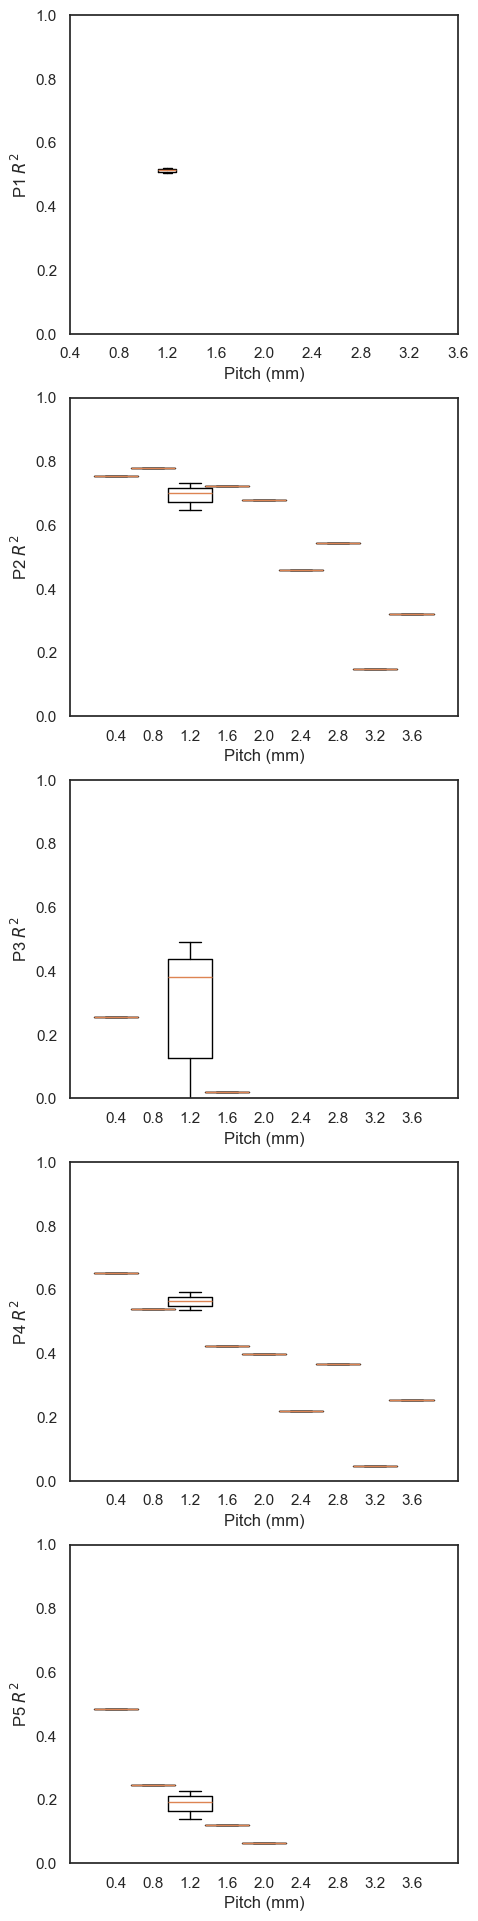

In [313]:
subject_list = [2,3,4,5,102005]
p_list = ["P1","P2","P3","P4","P5"]

f, ax = plt.subplots(5,1, figsize=(5, 24))

for i in range(5):
    pitchset = df[ (df['Subject']==subject_list[i]) & (df['Area'] > 16)]["Pitch"].unique()
    data = []
    positions = []
    for pitch in pitchset:
        data.append(df[ (df['Subject']==subject_list[i]) & (df['Area'] > 16) & (df["Pitch"] == pitch)]["Mean R2"].to_numpy())
    ax[i].boxplot(data, positions=pitchset)

    #sns.boxplot(data = df[ (df['Subject']==subject_list[i]) & (df['Area'] > 16)], 
    #                y='Mean R2',
    #                x='Pitch', 
    #                #order = [32.0, 16, 11, 10, 8,7,6,5,4], 
    #                dodge=True,
    #                #hue="Spacing", 
    #                #palette = 'viridis', 
    #                ax = ax[i], 
    #                legend=False)
    ax[i].grid(False)
    ax[i].set_xticks([0.4, 0.8, 1.2, 1.6, 2.0, 2.4, 2.8, 3.2,3.6 ])
    ax[i].set_xticklabels([0.4, 0.8, 1.2, 1.6, 2.0, 2.4, 2.8, 3.2,3.6 ])
    ax[i].set_ylim([0,1])
    ax[i].set_xlabel('Pitch (mm)')
    ax[i].set_ylabel(f'{p_list[i]} '+r'$R^2$')

C:\Users\Becca\AppData\Roaming\Python\Python312\site-packages\numpy\_core\fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
C:\Users\Becca\AppData\Roaming\Python\Python312\site-packages\numpy\_core\_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
C:\Users\Becca\AppData\Roaming\Python\Python312\site-packages\numpy\_core\fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
C:\Users\Becca\AppData\Roaming\Python\Python312\site-packages\numpy\_core\_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


(-0.5, 1.0)

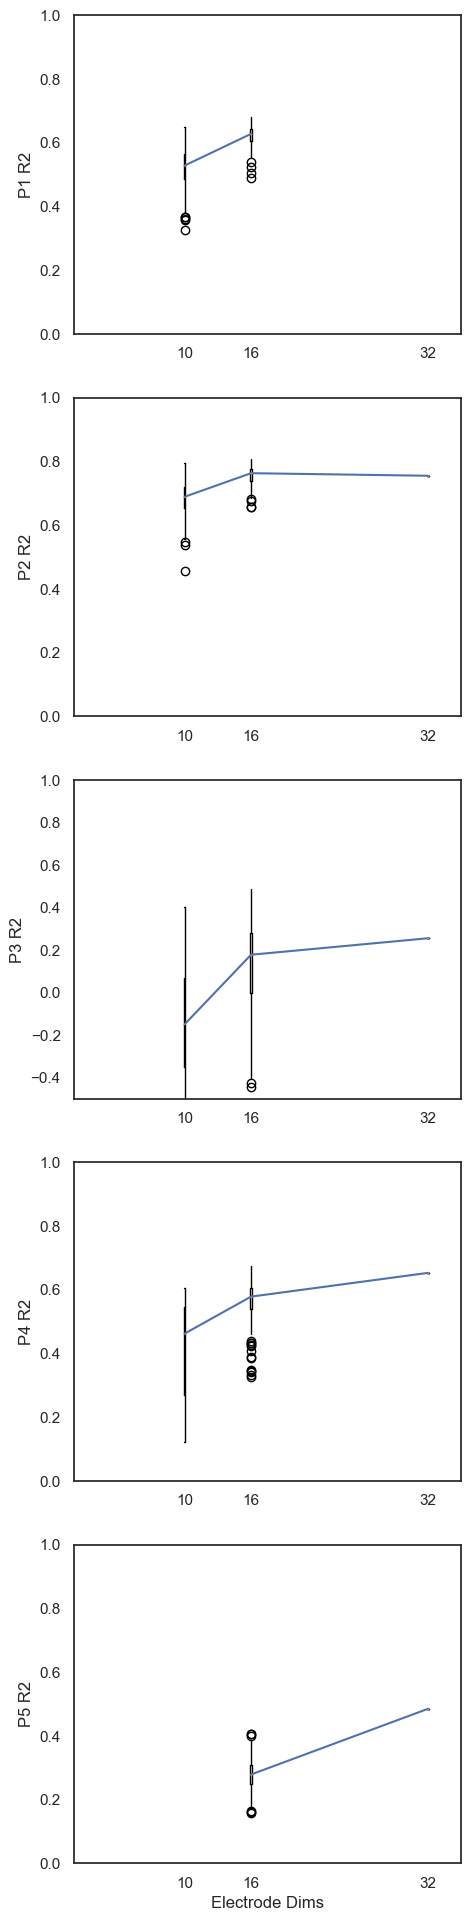

In [309]:
subject_list = [2,3,4,5,102005]
p_list = ["P1","P2","P3","P4","P5"]

f, ax = plt.subplots(5,1, figsize=(5, 24))


sns.set_style("white")
for i in range(5):
    meds = []
    for e_dim in [10,16,32]:
        ax[i].boxplot(df[ (df['Subject']==subject_list[i]) & (df['Spacing'] == "1.0") & ( df["Count"] == e_dim ) ]["Mean R2"], positions = [e_dim])
        
        meds.append(np.median(df[ (df['Subject']==subject_list[i]) & (df['Spacing'] == "1.0") & ( df["Count"] == e_dim ) ]["Mean R2"]))
    ax[i].plot([10,16,32], meds)
    #ax[i].set_yticks([0,10])
    #ax[i].set_yticklabels([32,4])
    #ax[i].set_xlabel("")
    ax[i].set_ylabel(f'{p_list[i]} R2')
    #ax[i].set_xlabel('Electrode Dims')
    ax[i].set_xlim([0,35])
    ax[i].set_ylim(0,1)
ax[i].set_xlabel('Electrode Dims')
ax[2].set_ylim(-.5,1)
#for i in range(4,5):
#    sns.stripplot(data = df[df['Subject']==subject_list[i]], x='Mean R2', y='Count', order = [32.0, 16, 11, 10, 8,7,6,5,4], dodge=True, hue="Spacing", palette = 'viridis', ax = ax[i], legend=False)
    #ax[i].set_yticks([0,10])
    #ax[i].set_yticklabels([32,4])
    #ax[i].set_ylabel(f'{p_list[i]} Grid Dims')  
    #ax[i].set_xlabel("R2")

['32', '16', '11', '10', '8', '7', '6', '5', '4']
['32', '16', '11', '10', '8', '7', '6', '5', '4']
['32', '16', '11', '10', '8', '7', '6', '5', '4']
['32', '16', '11', '10', '8', '7', '6', '5', '4']
['32', '16', '11', '10', '8', '7', '6', '5', '4']


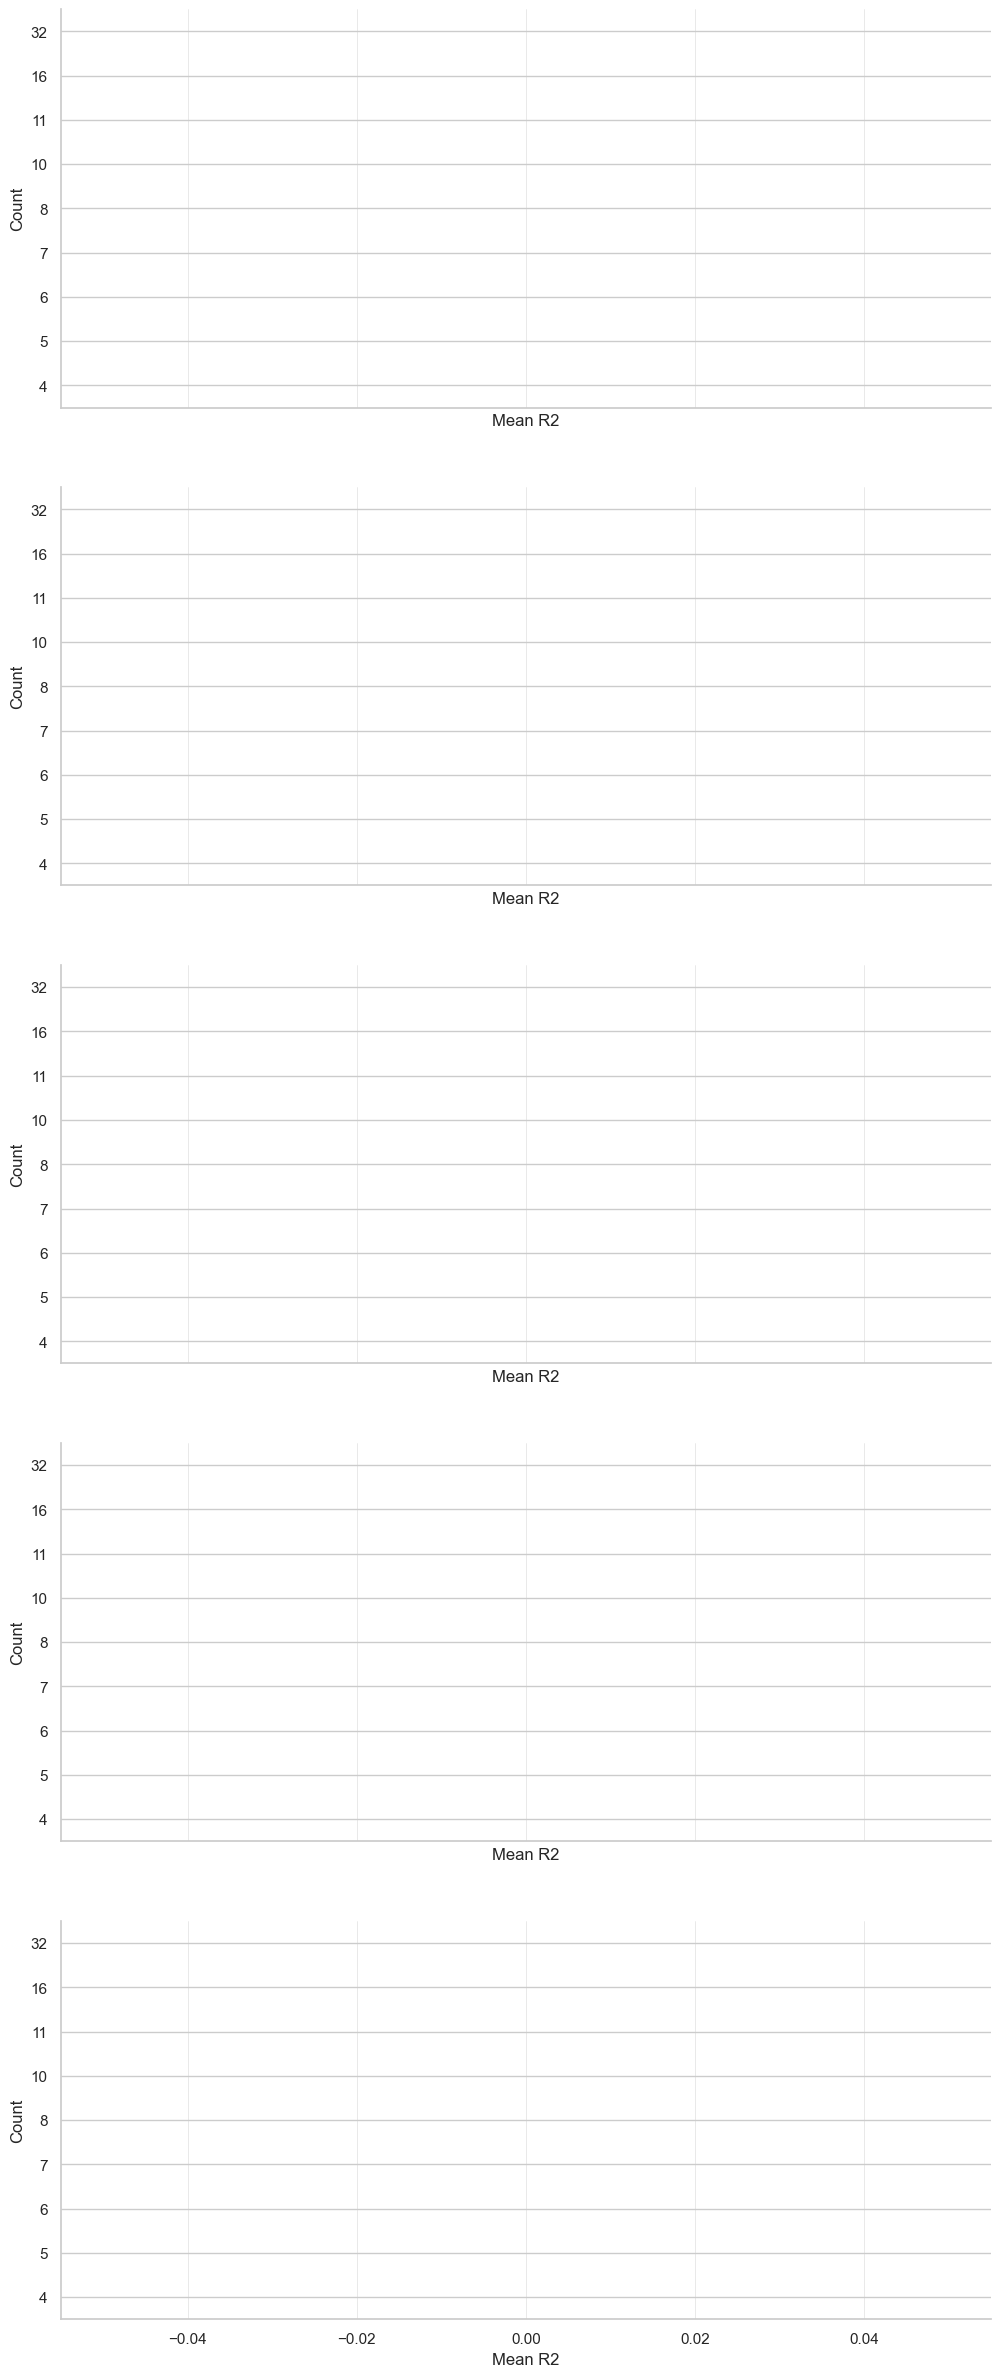

In [255]:
fig, axes = plt.subplots(len(subject_list), 1,
                         figsize=(12,6 * len(subject_list)),
                         sharex=True)
 
for i, subject in enumerate(subject_list):
    ax = axes[i] if len(subject_list) > 1 else axes
    stripplot_alpha(
        data      = df[df['Subject'] == subject],
        x         = 'Mean R2',
        y         = 'Count',
        hue       = 'Spacing',
        order     = [str(c) for c in [32, 16, 11, 10, 8, 7, 6, 5, 4]],
        ax        = ax,
        palette   = 'viridis',
        alpha_min = 0.15,
        alpha_max = 0.90,
        jitter    = 0.6,
        point_size= 4.0,
        dodge     = True,
    )

# 10x10 -- default config

In [64]:
file_list = ["D:\\Becca\\PN\\results\\decimate\\density1v02_size10_default.csv", # has P1 some positions
             "D:\\Becca\\PN\\\\density1v2_size10_default.csv",
             "D:\\Becca\\PN\\results\\decimate\\density2_size10_default.csv",
             "D:\\Becca\\PN\\results\\decimate\\density3_size10_default.csv"]
             
df = None
for file in file_list:            
    df_temp = pd.read_csv(file)
    df_temp = df_temp[df_temp['Subject'] != "Subject" ] 
    df_temp = df_temp[df_temp['Subject'].notna()] 

    df_temp['densityfactor'] = df_temp['densityfactor'].astype(float)
    df_temp['Spacing'] = (1/df_temp['densityfactor']).astype(str)
    df_temp['Subject'] = df_temp['Subject'].astype(int)
    df_temp['grid_pos'] = df_temp['grid_pos'].astype(int)

    df_temp['Mean R2'] = df_temp['R2'].astype(float)/2
    df_temp['R2'] = df_temp['R2'].astype(float)
    df_temp['mse'] = df_temp['mse'].astype(float)

    if df is not None:
        df = pd.concat([df, df_temp], axis=0)
    else: 
        df = df_temp.copy(deep=True)



Text(0.5, 1.0, '% MSE 10x10')

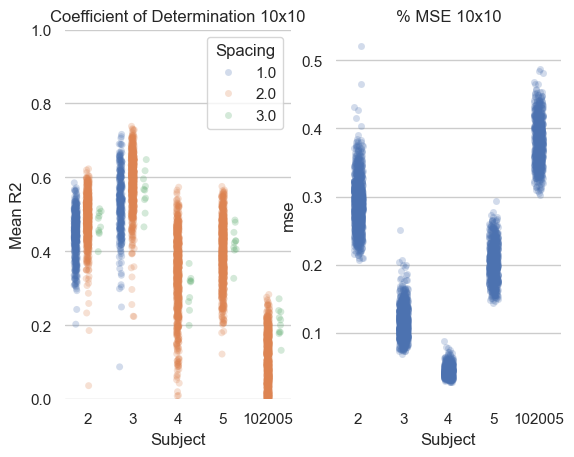

In [65]:
sns.set_theme(style="whitegrid")

# Initialize the figure
f, ax = plt.subplots(1,2)
sns.despine(bottom=True, left=True)

#ax.set_xticks([-1, -0.5, 0, 0.5, 1, 1.5, 2])

# Show each observation with a scatterplot
sns.stripplot(
    data=df, x="Subject", y="Mean R2",hue="Spacing",
    dodge=True, alpha=.25, zorder=1, legend=True, ax=ax[0]
)

ax[0].set_title("Coefficient of Determination 10x10")
ax[0].set_ylim([0,1])

# Show each observation with a scatterplot
sns.stripplot(
    data=df, x="Subject", y="mse",
    dodge=True, alpha=.25, zorder=1, legend=True, ax=ax[1]
)

plt.title("% MSE 10x10")

Using default channels, all inbound electrodes will be included.


C:\Users\Becca\AppData\Local\Temp\ipykernel_28480\1323057136.py:27: RuntimeWarning: invalid value encountered in divide
  p1 = ax[0].pcolor(map_r2_sum / map_count,  cmap='viridis' )
C:\Users\Becca\AppData\Local\Temp\ipykernel_28480\1323057136.py:31: RuntimeWarning: invalid value encountered in divide
  p2 = ax[1].pcolor(map_mse_sum / map_count, cmap='viridis' )


<Figure size 640x480 with 0 Axes>

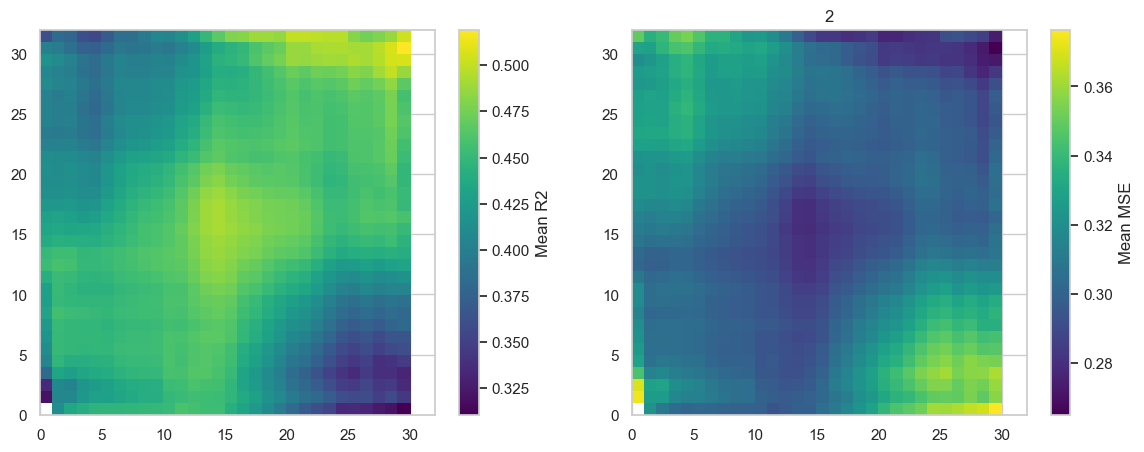

<Figure size 640x480 with 0 Axes>

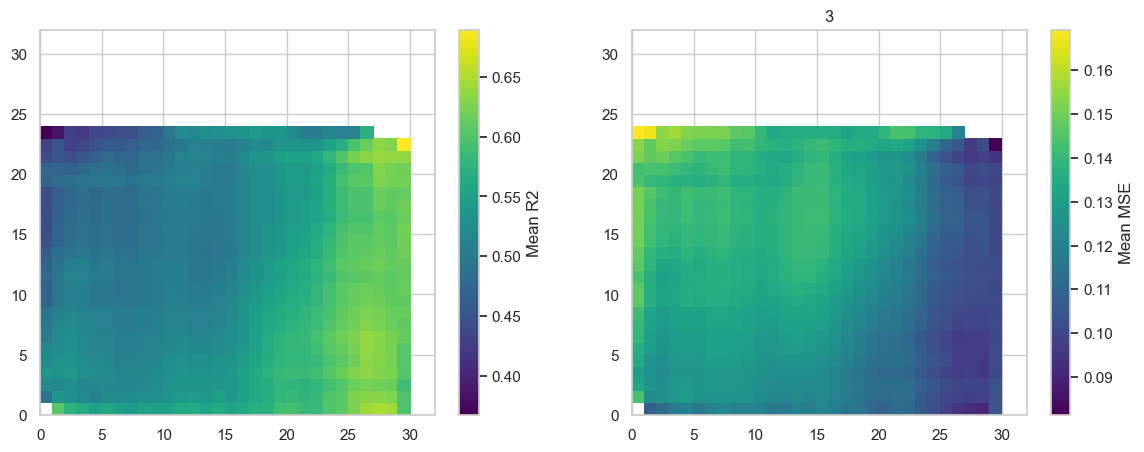

In [48]:
probe_map_path =  '../config/Precision_map_v2.xml'
DATA_ROOT = '/home/becca/Data/PN_preprocessed/' 
map = pos_to_electrode_map(probe_map_path)
set_list_10 = get_electrode_subsets(map, [10], density=1)


for subject in [2,3]:
    df_subject =  df[df['Subject'] == subject]
    
    
    #calculate mean r2
    map_r2_sum = np.zeros([32,32])
    map_mse_sum = np.zeros([32,32])
    map_count = np.zeros([32,32])
    
    for row_num in range(len(df_subject)):
        data_point = df_subject.iloc[row_num]
        point_set = set_list_10[data_point['grid_pos']-1]
        for x in point_set[0]:
            for y in point_set[1]:
                map_r2_sum[x,y] += data_point['Mean R2']
                map_mse_sum[x,y] += data_point['mse']
                map_count[x,y] += 1
    
    plt.figure()
    fig,ax = plt.subplots(1,2, figsize=(14,5))
    p1 = ax[0].pcolor(map_r2_sum / map_count,  cmap='viridis' )
    cbar = fig.colorbar(p1)
    cbar.set_label("Mean R2")

    p2 = ax[1].pcolor(map_mse_sum / map_count, cmap='viridis' )
    cbar1 = fig.colorbar(p2)
    cbar1.set_label("Mean MSE")
    plt.title(subject)

# 10x 10 -- Individual Configs

In [39]:
filepath = "D:\\Becca\\PN\\results\\decimate\\density1_size10.csv"
df = pd.read_csv(filepath)
df= df[df['Subject'] != "Subject" ] 

#print(df)
df['grid_pos'] = df['grid_pos'].astype(int)
df['Mean R2'] = df['R2'].astype(float)/2
df['mse'] = df['mse'].astype(float)

Text(0.5, 1.0, '% MSE 10x10')

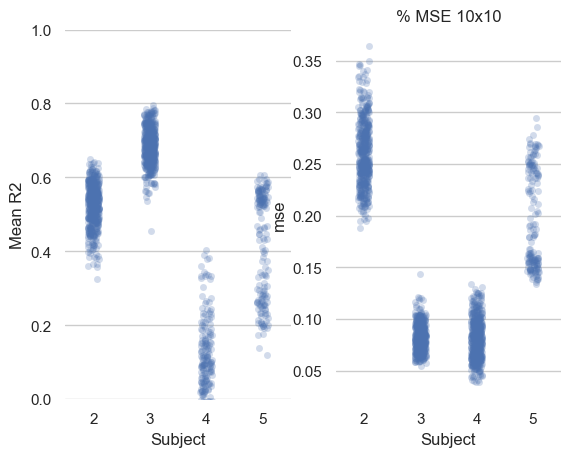

In [41]:
sns.set_theme(style="whitegrid")

# Initialize the figure
f, ax = plt.subplots(1,2)
sns.despine(bottom=True, left=True)

#ax.set_xticks([-1, -0.5, 0, 0.5, 1, 1.5, 2])

# Show each observation with a scatterplot
sns.stripplot(
    data=df, x="Subject", y="Mean R2",
    dodge=True, alpha=.25, zorder=1, legend=True, ax=ax[0]
)
ax[0].set_ylim([0,1])
plt.title("Coefficient of Determination 10x10")

# Show each observation with a scatterplot
sns.stripplot(
    data=df, x="Subject", y="mse",
    dodge=True, alpha=.25, zorder=1, legend=True, ax=ax[1]
)

plt.title("% MSE 10x10")

Using default channels, all inbound electrodes will be included.


C:\Users\Becca\AppData\Local\Temp\ipykernel_8584\1333683400.py:27: RuntimeWarning: invalid value encountered in divide
  p1 = ax[0].pcolor(map_r2_sum / map_count,  cmap='viridis' )
C:\Users\Becca\AppData\Local\Temp\ipykernel_8584\1333683400.py:31: RuntimeWarning: invalid value encountered in divide
  p2 = ax[1].pcolor(map_mse_sum / map_count, cmap='viridis' )


<Figure size 640x480 with 0 Axes>

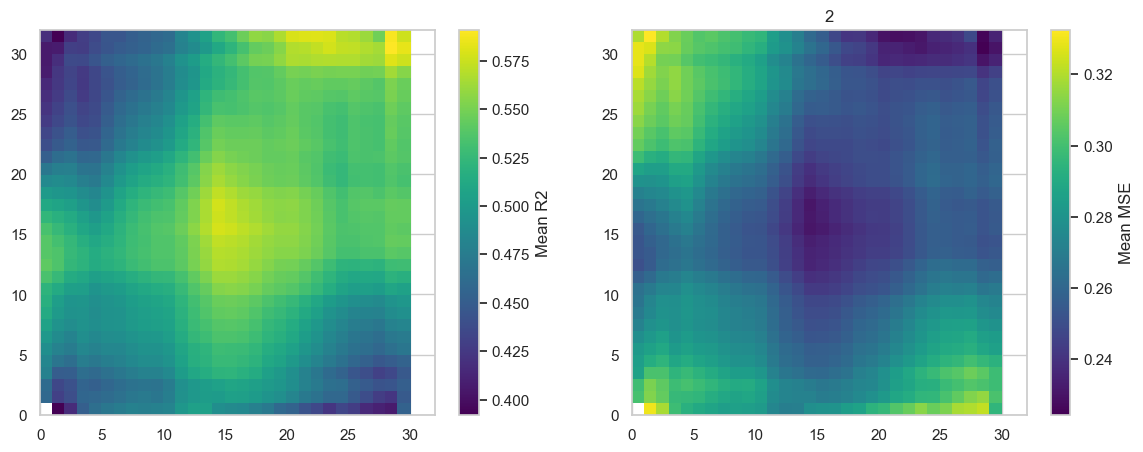

<Figure size 640x480 with 0 Axes>

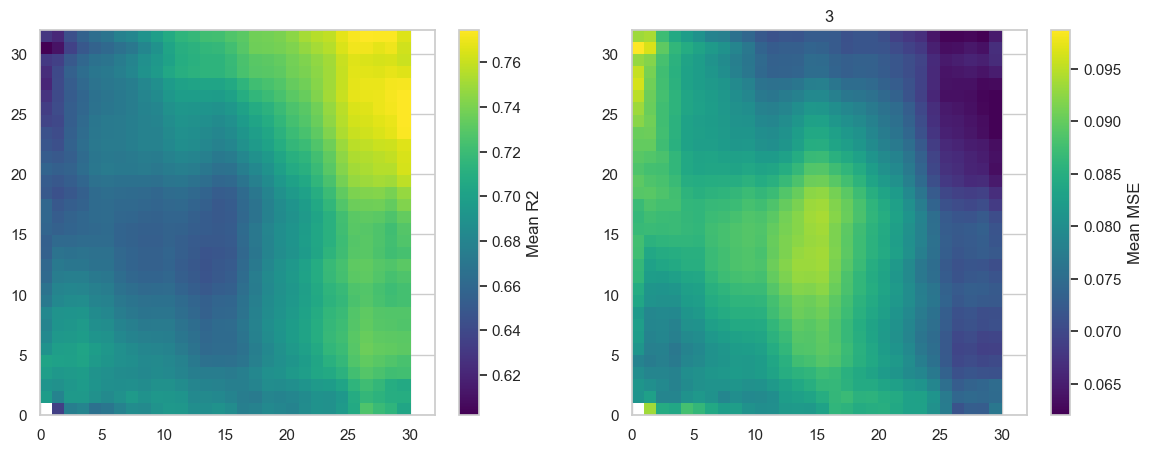

<Figure size 640x480 with 0 Axes>

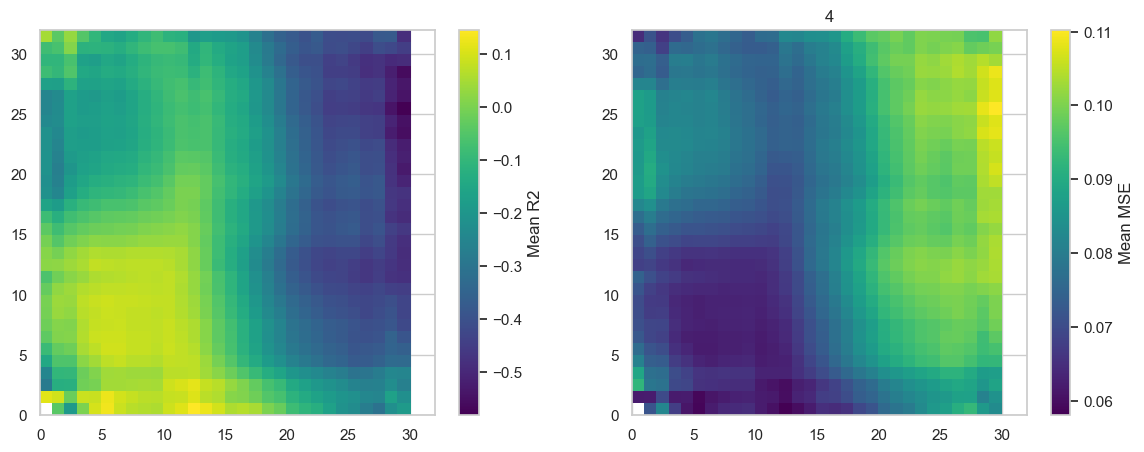

<Figure size 640x480 with 0 Axes>

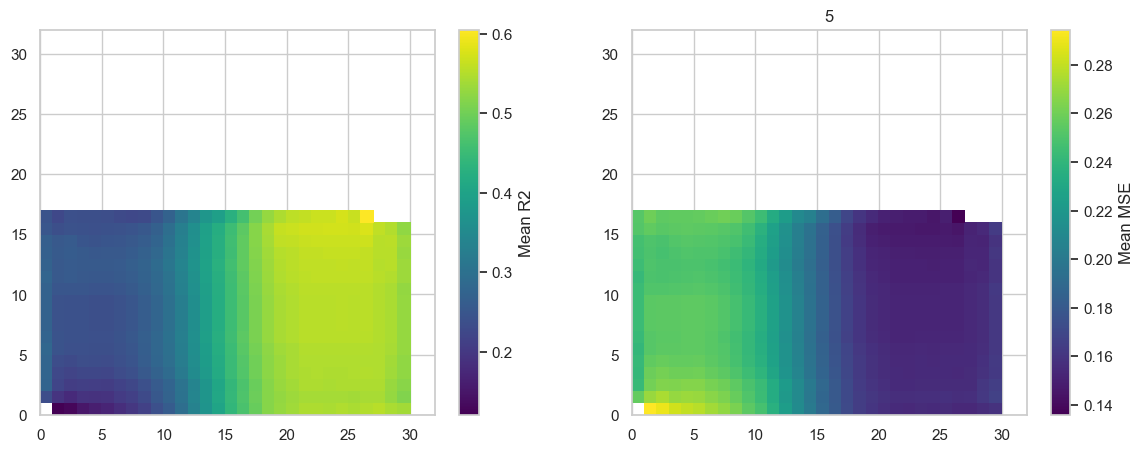

In [49]:
probe_map_path =  '../config/Precision_map_v2.xml'
DATA_ROOT = '/home/becca/Data/PN_preprocessed/' 
map = pos_to_electrode_map(probe_map_path)
set_list_10 = get_electrode_subsets(map, [10], density=1)


for subject in ["2","3", "4","5"]:
    df_subject =  df[df['Subject'] == subject]
    
    
    #calculate mean r2
    map_r2_sum = np.zeros([32,32])
    map_mse_sum = np.zeros([32,32])
    map_count = np.zeros([32,32])
    
    for row_num in range(len(df_subject)):
        data_point = df_subject.iloc[row_num]
        point_set = set_list_10[data_point['grid_pos']-1]
        for x in point_set[0]:
            for y in point_set[1]:
                map_r2_sum[x,y] += data_point['Mean R2']
                map_mse_sum[x,y] += data_point['mse']
                map_count[x,y] += 1
    
    plt.figure()
    fig,ax = plt.subplots(1,2, figsize=(14,5))
    p1 = ax[0].pcolor(map_r2_sum / map_count,  cmap='viridis' )
    cbar = fig.colorbar(p1)
    cbar.set_label("Mean R2")

    p2 = ax[1].pcolor(map_mse_sum / map_count, cmap='viridis' )
    cbar1 = fig.colorbar(p2)
    cbar1.set_label("Mean MSE")
    plt.title(subject)

In [30]:
df_subject.iloc[1]


Subject                           2
R2               0.8818346858024597
mse                        0.307158
gridsize                      10x10
densityfactor                     1
grid_pos                          2
Mean R2                    0.440917
Name: 3, dtype: object

# Looking at # electrodes, tailored config

In [66]:
file_list = ["D:\\Becca\\PN\\results\\decimate\\density1_size16.csv", # has P1 some positions
             "D:\\Becca\\PN\\results\\decimate\\density1_size10.csv",
             "D:\\Becca\\PN\\results\\decimate\\density_sweep_e30.csv"]
             
df = None
for file in file_list:            
    df_temp = pd.read_csv(file)
    df_temp = df_temp[df_temp['Subject'] != "Subject" ] 
    df_temp = df_temp[df_temp['Subject'].notna()] 

    df_temp['densityfactor'] = df_temp['densityfactor'].astype(float)
    df_temp['Spacing'] = (1/df_temp['densityfactor']).astype(int)
    df_temp['Subject'] = df_temp['Subject'].astype(str)
    df_temp['grid_pos'] = df_temp['grid_pos'].astype(int)
    df_temp['Count'] = df_temp['Count'].astype(int)


    df_temp['Mean R2'] = df_temp['R2'].astype(float)/2
    df_temp['R2'] = df_temp['R2'].astype(float)
    df_temp['mse'] = df_temp['mse'].astype(float)

    if df is not None:
        df = pd.concat([df, df_temp], axis=0)
    else: 
        df = df_temp.copy(deep=True)

ValueError: cannot reindex on an axis with duplicate labels

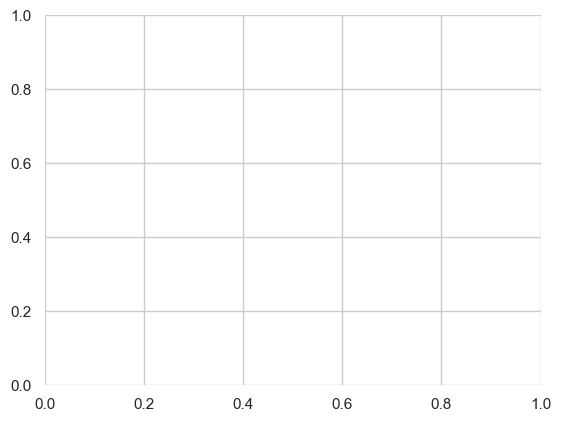

In [77]:
sns.set_theme(style="whitegrid")

# Initialize the figure
f, ax = plt.subplots()
sns.despine(bottom=True, left=True)

#ax.set_xticks([-1, -0.5, 0, 0.5, 1, 1.5, 2])

# Show each observation with a scatterplot
sns.stripplot(
    data=df, x="Count", y="Mean R2", hue="Subject",
    dodge=True, alpha=.25, zorder=1, legend=True,
)
ax.set_xlabel("Grid Size")
plt.title("Coefficient of Determination Density 1")

# From older 1d model version


In [3]:
file_16 = "/home/becca/Documents/pn/results/decimate_results_16.csv"
file_16_05 = "/home/becca/Documents/pn/decimate_results_16_05.csv"

In [4]:
df_16 = pd.read_csv(file_16)
df_16 = df_16[df_16['Subject'] != "Subject" ] 
df_16['R2'] = df_16['R2'].astype(float)

df_16_05 = pd.read_csv(file_16_05)
df_16_05 = df_16_05[df_16_05['Subject'] != "Subject" ] 
df_16_05['R2'] = df_16_05['R2'].astype(float)


df_all = pd.concat([df_16, df_16_05])
df_all['R2'] = df_all['R2'] /2 
df_all['densityfactor'] = df_all['densityfactor'].astype(float) 

Text(0.5, 1.0, 'Coefficient of Determination 16x16')

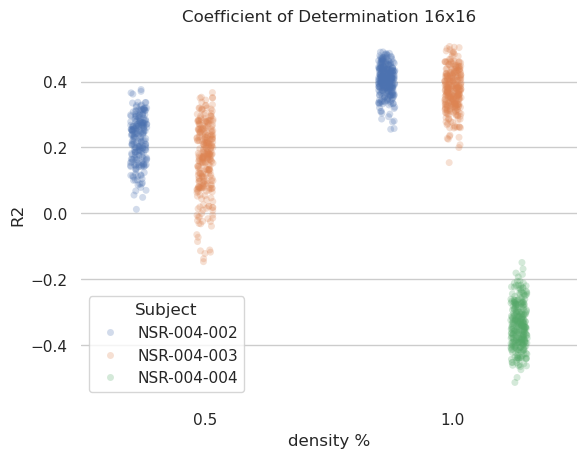

In [13]:
sns.set_theme(style="whitegrid")

# Initialize the figure
f, ax = plt.subplots()
sns.despine(bottom=True, left=True)

#ax.set_xticks([-1, -0.5, 0, 0.5, 1, 1.5, 2])

# Show each observation with a scatterplot
sns.stripplot(
    data=df_all, x="densityfactor", y="R2", hue="Subject",
    dodge=True, alpha=.25, zorder=1, legend=True,
)
ax.set_xlabel("density %")
plt.title("Coefficient of Determination 16x16")

In [ ]:
# fixed num electrodes, vary density 8x8

In [14]:
file_8_05 = "/home/becca/Documents/pn/results/decimate_results_8_05.csv"
file_8_03 = "/home/becca/Documents/pn/results/decimate_results_8_03.csv"
file_8_025 = "/home/becca/Documents/pn/results/decimate_results_8_025.csv"
file_8 = "/home/becca/Documents/pn/results/decimate_results_8.csv"

In [22]:
df_8 = pd.read_csv(file_8)
df_8 = df_8[df_8['Subject'] != "Subject" ] 
df_8['R2'] = df_8['R2'].astype(float)

df_08_05 = pd.read_csv(file_8_05)
df_08_05 = df_08_05[df_08_05['Subject'] != "Subject" ] 
df_08_05['R2'] = df_08_05['R2'].astype(float)

df_8_03 = pd.read_csv(file_8_03)
df_8_03 = df_8_03[df_8_03['Subject'] != "Subject" ] 
df_8_03['R2'] = df_8_03['R2'].astype(float)

df_8_025 = pd.read_csv(file_8_025)
df_8_025 = df_8_025[df_8_025['Subject'] != "Subject" ] 
df_8_025['R2'] = df_8_025['R2'].astype(float)

df_all = pd.concat([df_08_05, df_8_03,df_8, df_8_025])
df_all['R2'] = df_all['R2'] /2 
df_all['densityfactor'] = df_all['densityfactor'].astype(float) 


Text(0.5, 0, 'density %')

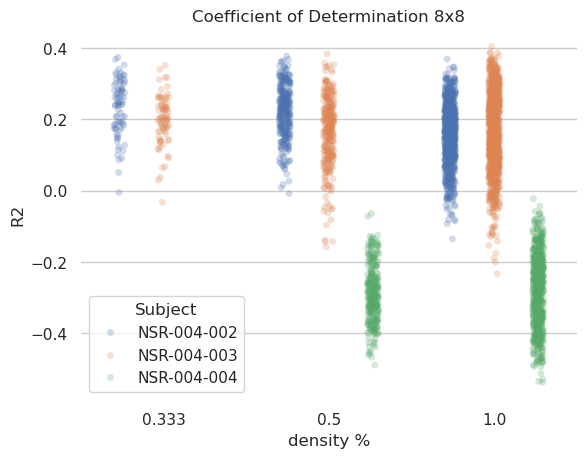

In [23]:
sns.set_theme(style="whitegrid")

# Initialize the figure
f, ax = plt.subplots()
sns.despine(bottom=True, left=True)

#ax.set_xticks([-1, -0.5, 0, 0.5, 1, 1.5, 2])

# Show each observation with a scatterplot
sns.stripplot(
    data=df_all, x="densityfactor", y="R2", hue="Subject",
    dodge=True, alpha=.25, zorder=1, legend=True,
)

plt.title("Coefficient of Determination 8x8")
ax.set_xlabel("density %")

In [13]:
# same area, different density

In [14]:
file_grid_down =  "/home/becca/Documents/pn/results/decimate_results_grid_down.csv"
df_grid_down = pd.read_csv(file_grid_down)


        Subject        R2  gridsize  densityfactor  grid_pos  space_factor
0   NSR-004-002  1.005611         8           0.25       0.0           0.0
1   NSR-004-002  0.702743         8           0.25       1.0           1.0
2   NSR-004-002  0.634009         8           0.25       2.0           2.0
3   NSR-004-002  0.397845         8           0.25       3.0           3.0
4   NSR-004-002  0.373891         8           0.25       4.0           4.0
5   NSR-004-002  0.031318         8           0.25       5.0           5.0
6   NSR-004-002  0.276781         8           0.25       6.0           6.0
7   NSR-004-002 -0.018191         8           0.25       7.0           7.0
8   NSR-004-002  0.227017         8           0.25       8.0           8.0
9   NSR-004-002  0.131980         8           0.25       9.0           9.0
10  NSR-004-003  1.095666         8           0.25       0.0           0.0
11  NSR-004-003  0.844025         8           0.25       1.0           1.0
12  NSR-004-003  0.699523

Text(0.5, 1.0, 'Coefficient of Determination')

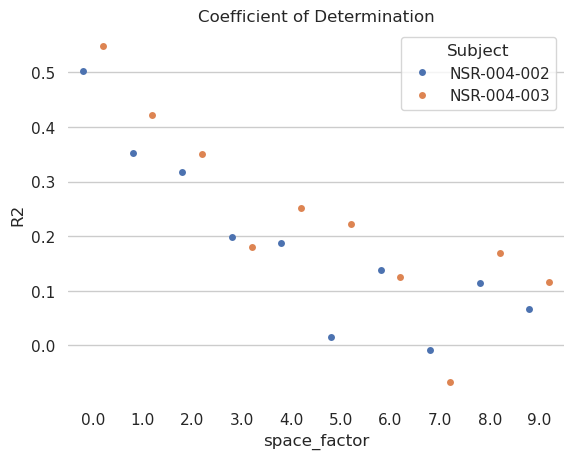

In [24]:
print(df_grid_down)

df_grid_down['R2'] = df_grid_down['R2'].astype(float) / 2
df_grid_down['grid_pos'] = df_grid_down['grid_pos'].astype(float)
df_grid_down['space_factor'] = df_grid_down['grid_pos'].astype(float)

sns.set_theme(style="whitegrid")

# "Melt" the dataset to "long-form" or "tidy" representation
#iris = iris.melt(id_vars="species", var_name="measurement")

# Initialize the figure
f, ax = plt.subplots()
sns.despine(bottom=True, left=True)


#ax.set_xticks([-1, -0.5, 0, 0.5, 1, 1.5, 2])


# Show each observation with a scatterplot
sns.stripplot(
    data=df_grid_down, x="space_factor", y="R2", hue="Subject",
    dodge=True, alpha=1, zorder=1, legend=True,
)

plt.title("Coefficient of Determination")

In [12]:
# Same Density, Smaller grid

In [4]:
file_16 = "/home/becca/Documents/pn/results/decimate_results_16.csv"
file_8 = "/home/becca/Documents/pn/results/decimate_results_8.csv"
file_full = "/home/becca/Documents/pn/results/decimate_results_full.csv"

In [5]:
df_16 = pd.read_csv(file_16)
df_16 = df_16[df_16['Subject'] != "Subject"]
df_16['R2'] = df_16['R2'].astype(float)

df_8 = pd.read_csv(file_8)
df_8 = df_8[df_8['Subject'] != "Subject"]
df_8['R2'] = df_8['R2'].astype(float) 

df_full = pd.read_csv(file_full)
df_full = df_full[df_full['Subject'] != "Subject"]
df_full['R2'] = df_full['R2'].astype(float) 

# remove entries that aren't numbers 



In [6]:
df_all = pd.concat([df_16, df_8, df_full])
df_all['R2'] = df_all['R2'] /2 


Text(0.5, 1.0, 'Coefficient of Determination')

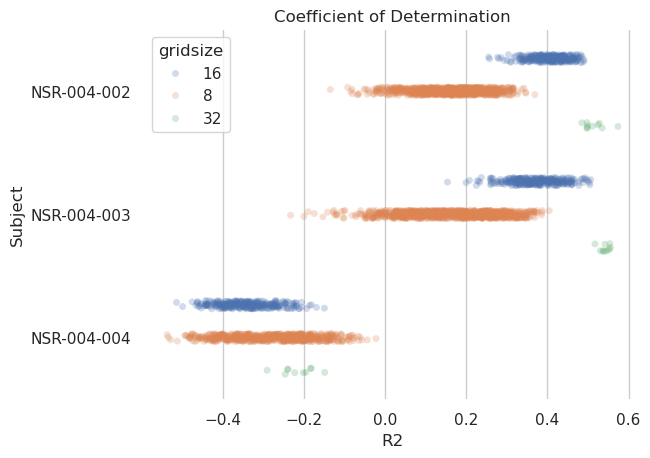

In [7]:
sns.set_theme(style="whitegrid")

# "Melt" the dataset to "long-form" or "tidy" representation
#iris = iris.melt(id_vars="species", var_name="measurement")

# Initialize the figure
f, ax = plt.subplots()
sns.despine(bottom=True, left=True)


#ax.set_xticks([-1, -0.5, 0, 0.5, 1, 1.5, 2])


# Show each observation with a scatterplot
sns.stripplot(
    data=df_all, x="R2", y="Subject", hue="gridsize",
    dodge=True, alpha=.25, zorder=1, legend=True,
)

plt.title("Coefficient of Determination")
# Show the conditional means, aligning each pointplot in the
# center of the strips by adjusting the width allotted to each
# category (.8 by default) by the number of hue levels
#sns.pointplot(
#    data=iris, x="value", y="measurement", hue="species",
#    dodge=.8 - .8 / 3, palette="dark", errorbar=None,
#    markers="d", markersize=4, linestyle="none",
#)

# Improve the legend
#sns.move_legend(
#    ax, loc="lower right", ncol=3, frameon=True, columnspacing=1, handletextpad=0,
#)


In [8]:
probe_map_path =  '../config/Precision_map_v2.xml'
DATA_ROOT = '/home/becca/Data/PN_preprocessed/' 
map = pos_to_electrode_map(probe_map_path)
set_list_16 = get_electrode_subsets(map, [16], density=1)

subject = "NSR-004-002"

df_16_subject =  df_16[df_16['Subject'] == subject]



Using default channels, all inbound electrodes will be included.


Using default channels, all inbound electrodes will be included.


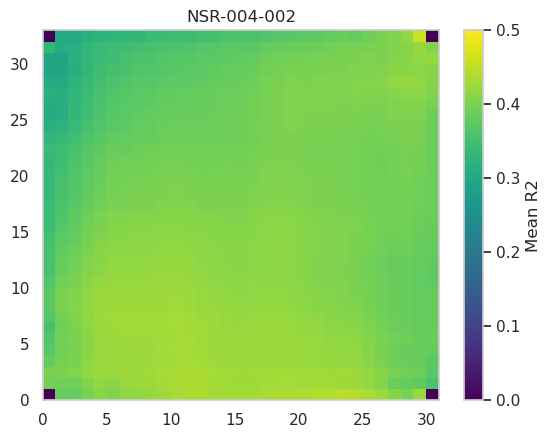

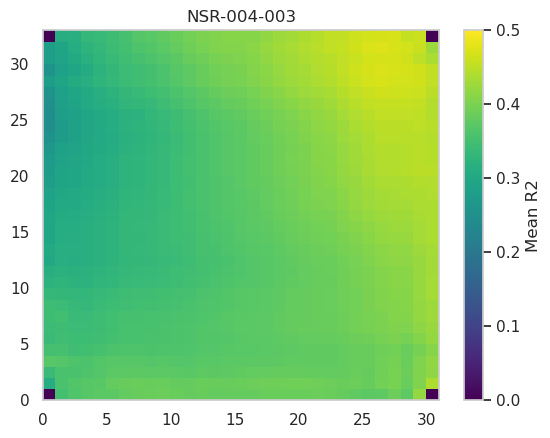

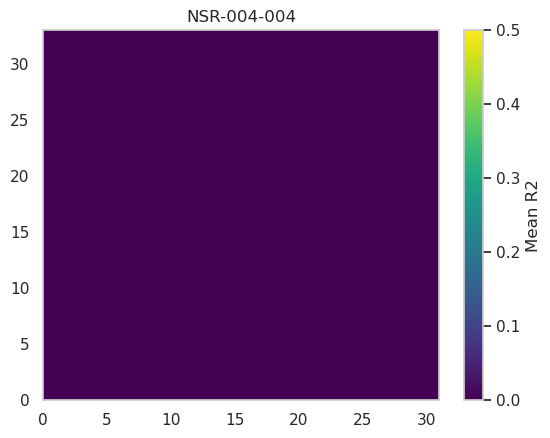

In [11]:
probe_map_path =  '../config/Precision_map_v2.xml'
DATA_ROOT = '/home/becca/Data/PN_preprocessed/' 
map = pos_to_electrode_map(probe_map_path)
set_list_16 = get_electrode_subsets(map, [16], density=1)

subject = "NSR-004-002"

for subject in ["NSR-004-002", "NSR-004-003","NSR-004-004"]:
    df_16_subject =  df_16[df_16['Subject'] == subject]
    
    
    #calculate mean r2
    map_sum = np.zeros([1024])
    map_count = np.zeros([1024])
    
    for row_num in range(len(df_16_subject)):
        data_point = df_16_subject.iloc[row_num]
        point_set = set_list_16[data_point['grid_pos']]
        for electrode in point_set:
            map_sum[int(electrode)] += data_point['R2'] / 2
            map_count[int(electrode)] += 1
    
    ## Plot results 
    map_shape = np.shape(map)
    result_grid = np.zeros(map_shape)
    for x in range(map_shape[0]):
        for y in range(map_shape[1]):
            electrode = int(map[x,y]) 
            count = map_count[electrode]
            if (count >0):
                result_grid[x,y] = map_sum[electrode] / count
    
    plt.figure()
    plt.pcolor(result_grid, vmin=0, vmax=0.5, cmap='viridis' )
    cbar = plt.colorbar()
    cbar.set_label("Mean R2")
    plt.title(subject)


Using default channels, all inbound electrodes will be included.


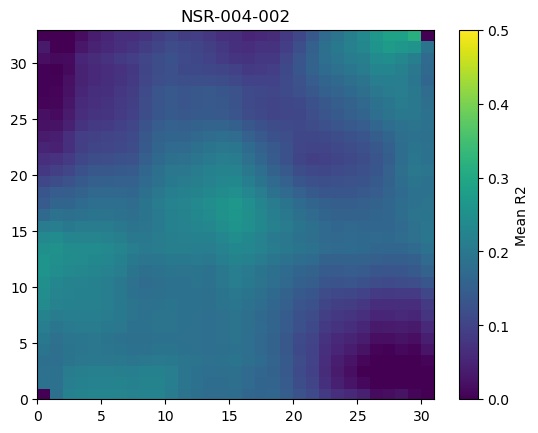

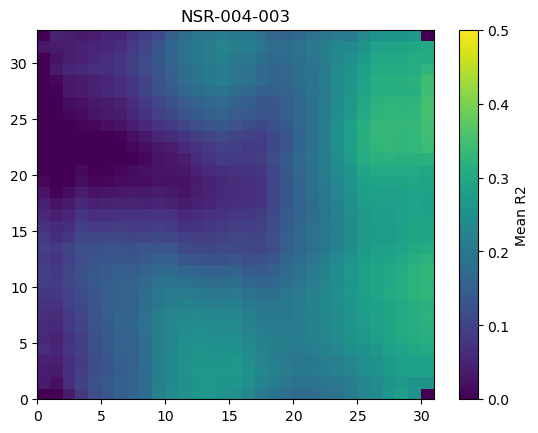

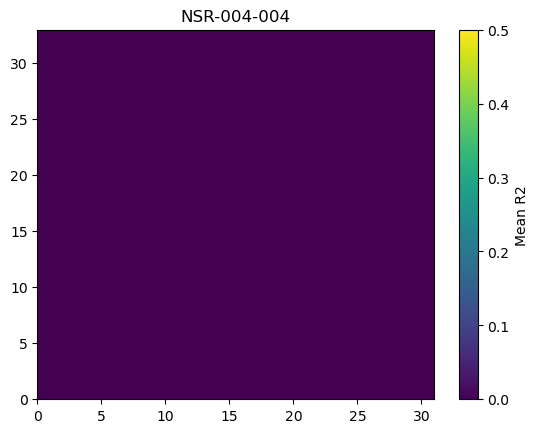

In [75]:
probe_map_path =  '../config/Precision_map_v2.xml'
DATA_ROOT = '/home/becca/Data/PN_preprocessed/' 
map = pos_to_electrode_map(probe_map_path)
set_list_8 = get_electrode_subsets(map, [8], density=1)

subject = "NSR-004-002"

for subject in ["NSR-004-002", "NSR-004-003","NSR-004-004"]:
    df_8_subject =  df_8[df_8['Subject'] == subject]
    
    
    #calculate mean r2
    map_sum = np.zeros([1024])
    map_count = np.zeros([1024])
    
    for row_num in range(len(df_8_subject)):
        data_point = df_8_subject.iloc[row_num]
        point_set = set_list_8[int(data_point['grid_pos'])]
        for electrode in point_set:
            map_sum[int(electrode)] += data_point['R2'] /2
            map_count[int(electrode)] += 1
    
    ## Plot results 
    map_shape = np.shape(map)
    result_grid = np.zeros(map_shape)
    for x in range(map_shape[0]):
        for y in range(map_shape[1]):
            electrode = int(map[x,y]) 
            count = map_count[electrode]
            if (count >0):
                result_grid[x,y] = map_sum[electrode] / count
    
    plt.figure()
    plt.pcolor(result_grid, vmin=0, vmax=0.5)
    cbar = plt.colorbar()
    cbar.set_label("Mean R2")
    plt.title(subject)

In [79]:
for i in range(16,32):
    print(i, len(get_electrode_subsets(map, [i], density=1) )  )

16 284
17 251
18 220
19 191
20 164
21 139
22 116
23 95
24 76
25 59
26 44
27 31
28 20
29 11
30 4
31 1
